<a class="anchor" id="0"></a>
# **Mubileum Duration Generation with VAE**

<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder



from sklearn.metrics import precision_recall_curve

# **2. Data Preparation** <a class="anchor" id="2"></a>

[Table of Contents](#0.1)

In [2]:
# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
# df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)


# Drop duplicates
df.drop_duplicates(inplace=True)

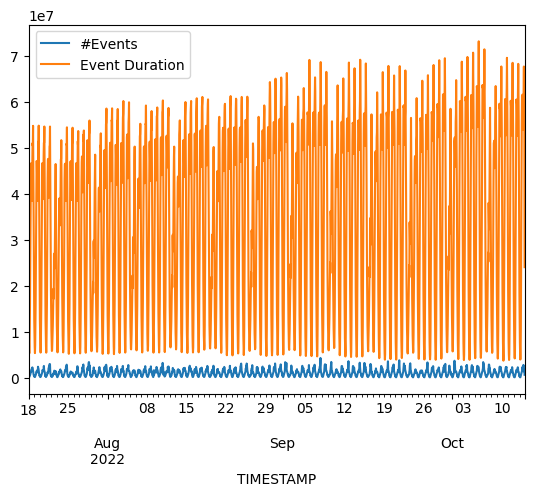

In [3]:
df[["#Events","Event Duration", "TIMESTAMP"]].groupby('TIMESTAMP').sum().plot()
plt.savefig('Events x Event Dura.png')  # Replace with your path and desired file name

# If you're using Jupyter notebooks or IPython, you might also need to close the figure explicitly

plt.show()

In [4]:
df.describe(include ="all").round()

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,Event Duration,TIMESTAMP
count,958613,958613,958613,958613,958613,958613,958613.0,958613.0,958613
unique,2,4,5,3,2,392,NaN,NaN,NaN
top,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0001,NaN,NaN,NaN
freq,504756,579200,845431,882775,939623,105549,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2396.0,75689.0,2022-08-31 16:35:43.330415360
min,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,2022-07-18 00:00:00
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2022-08-09 20:00:00
50%,NaN,NaN,NaN,NaN,NaN,NaN,9.0,0.0,2022-09-01 00:00:00
75%,NaN,NaN,NaN,NaN,NaN,NaN,59.0,74.0,2022-09-22 17:00:00
max,NaN,NaN,NaN,NaN,NaN,NaN,3053227.0,11008421.0,2022-10-13 21:00:00


In [5]:
df.describe()

,#Events,Event Duration,TIMESTAMP
count,9.586130e+05,9.586130e+05,958613
mean,2.395538e+03,7.568939e+04,2022-08-31 16:35:43.330415360
min,0.000000e+00,0.000000e+00,2022-07-18 00:00:00
25%,2.000000e+00,0.000000e+00,2022-08-09 20:00:00
50%,9.000000e+00,0.000000e+00,2022-09-01 00:00:00
75%,5.900000e+01,7.400000e+01,2022-09-22 17:00:00
max,3.053227e+06,1.100842e+07,2022-10-13 21:00:00
std,3.119232e+04,5.351563e+05,NaN


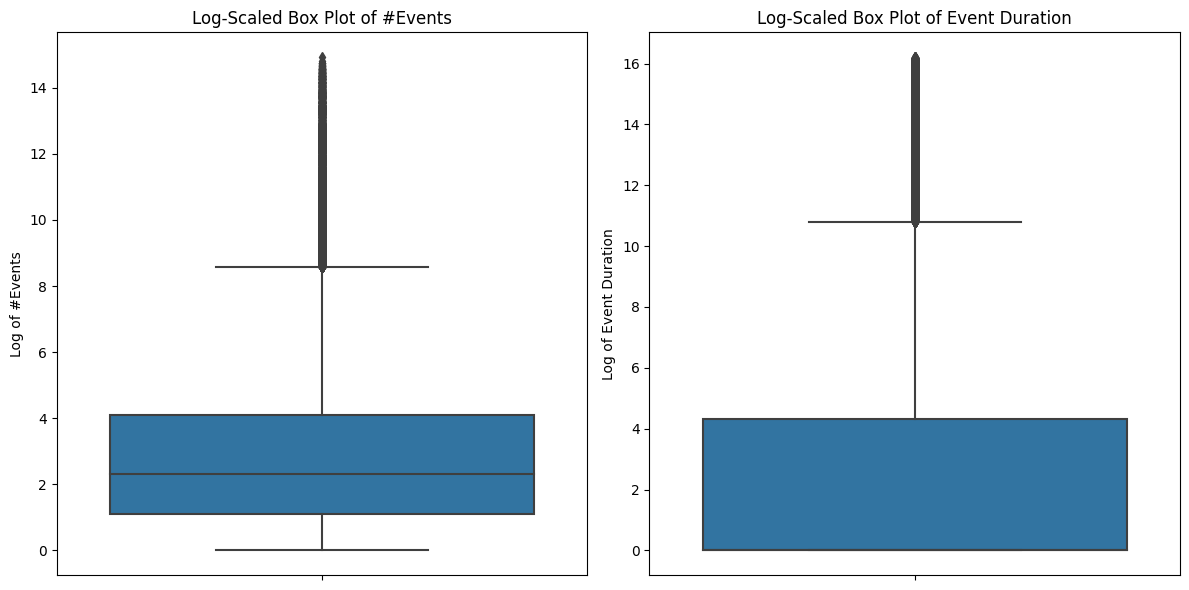

In [6]:
# Re-importing necessary libraries and reloading data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



plt.figure(figsize=(12, 6))

# Plotting box plots for #Events with log scale
plt.subplot(1, 2, 1)
# Adding a small value to avoid log(0) which is undefined
sns.boxplot(y=np.log1p(df['#Events']))  
plt.title('Log-Scaled Box Plot of #Events')
plt.ylabel('Log of #Events')

# Plotting box plots for Event Duration with log scale
plt.subplot(1, 2, 2)
# Adding a small value to avoid log(0) which is undefined
sns.boxplot(y=np.log1p(df['Event Duration']))  
plt.title('Log-Scaled Box Plot of Event Duration')
plt.ylabel('Log of Event Duration')
plt.savefig('Log Box Plot.png')

plt.tight_layout()
plt.show()

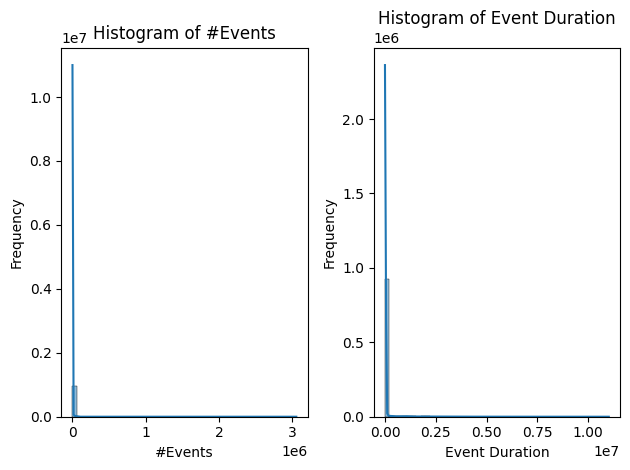

In [7]:
# Histogram for #Events
plt.subplot(1, 2, 1)
sns.histplot(df['#Events'], bins=50, kde=True)
plt.title('Histogram of #Events')
plt.xlabel('#Events')
plt.ylabel('Frequency')

# Histogram for Event Duration
plt.subplot(1, 2, 2)
sns.histplot(df['Event Duration'], bins=50, kde=True)
plt.title('Histogram of Event Duration')
plt.xlabel('Event Duration')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig('Histo Events.png')
plt.show()

# **3. EDA** <a class="anchor" id="3"></a>

[Table of Contents](#0.1)

In [8]:
df.to_csv("df.csv", index=False)

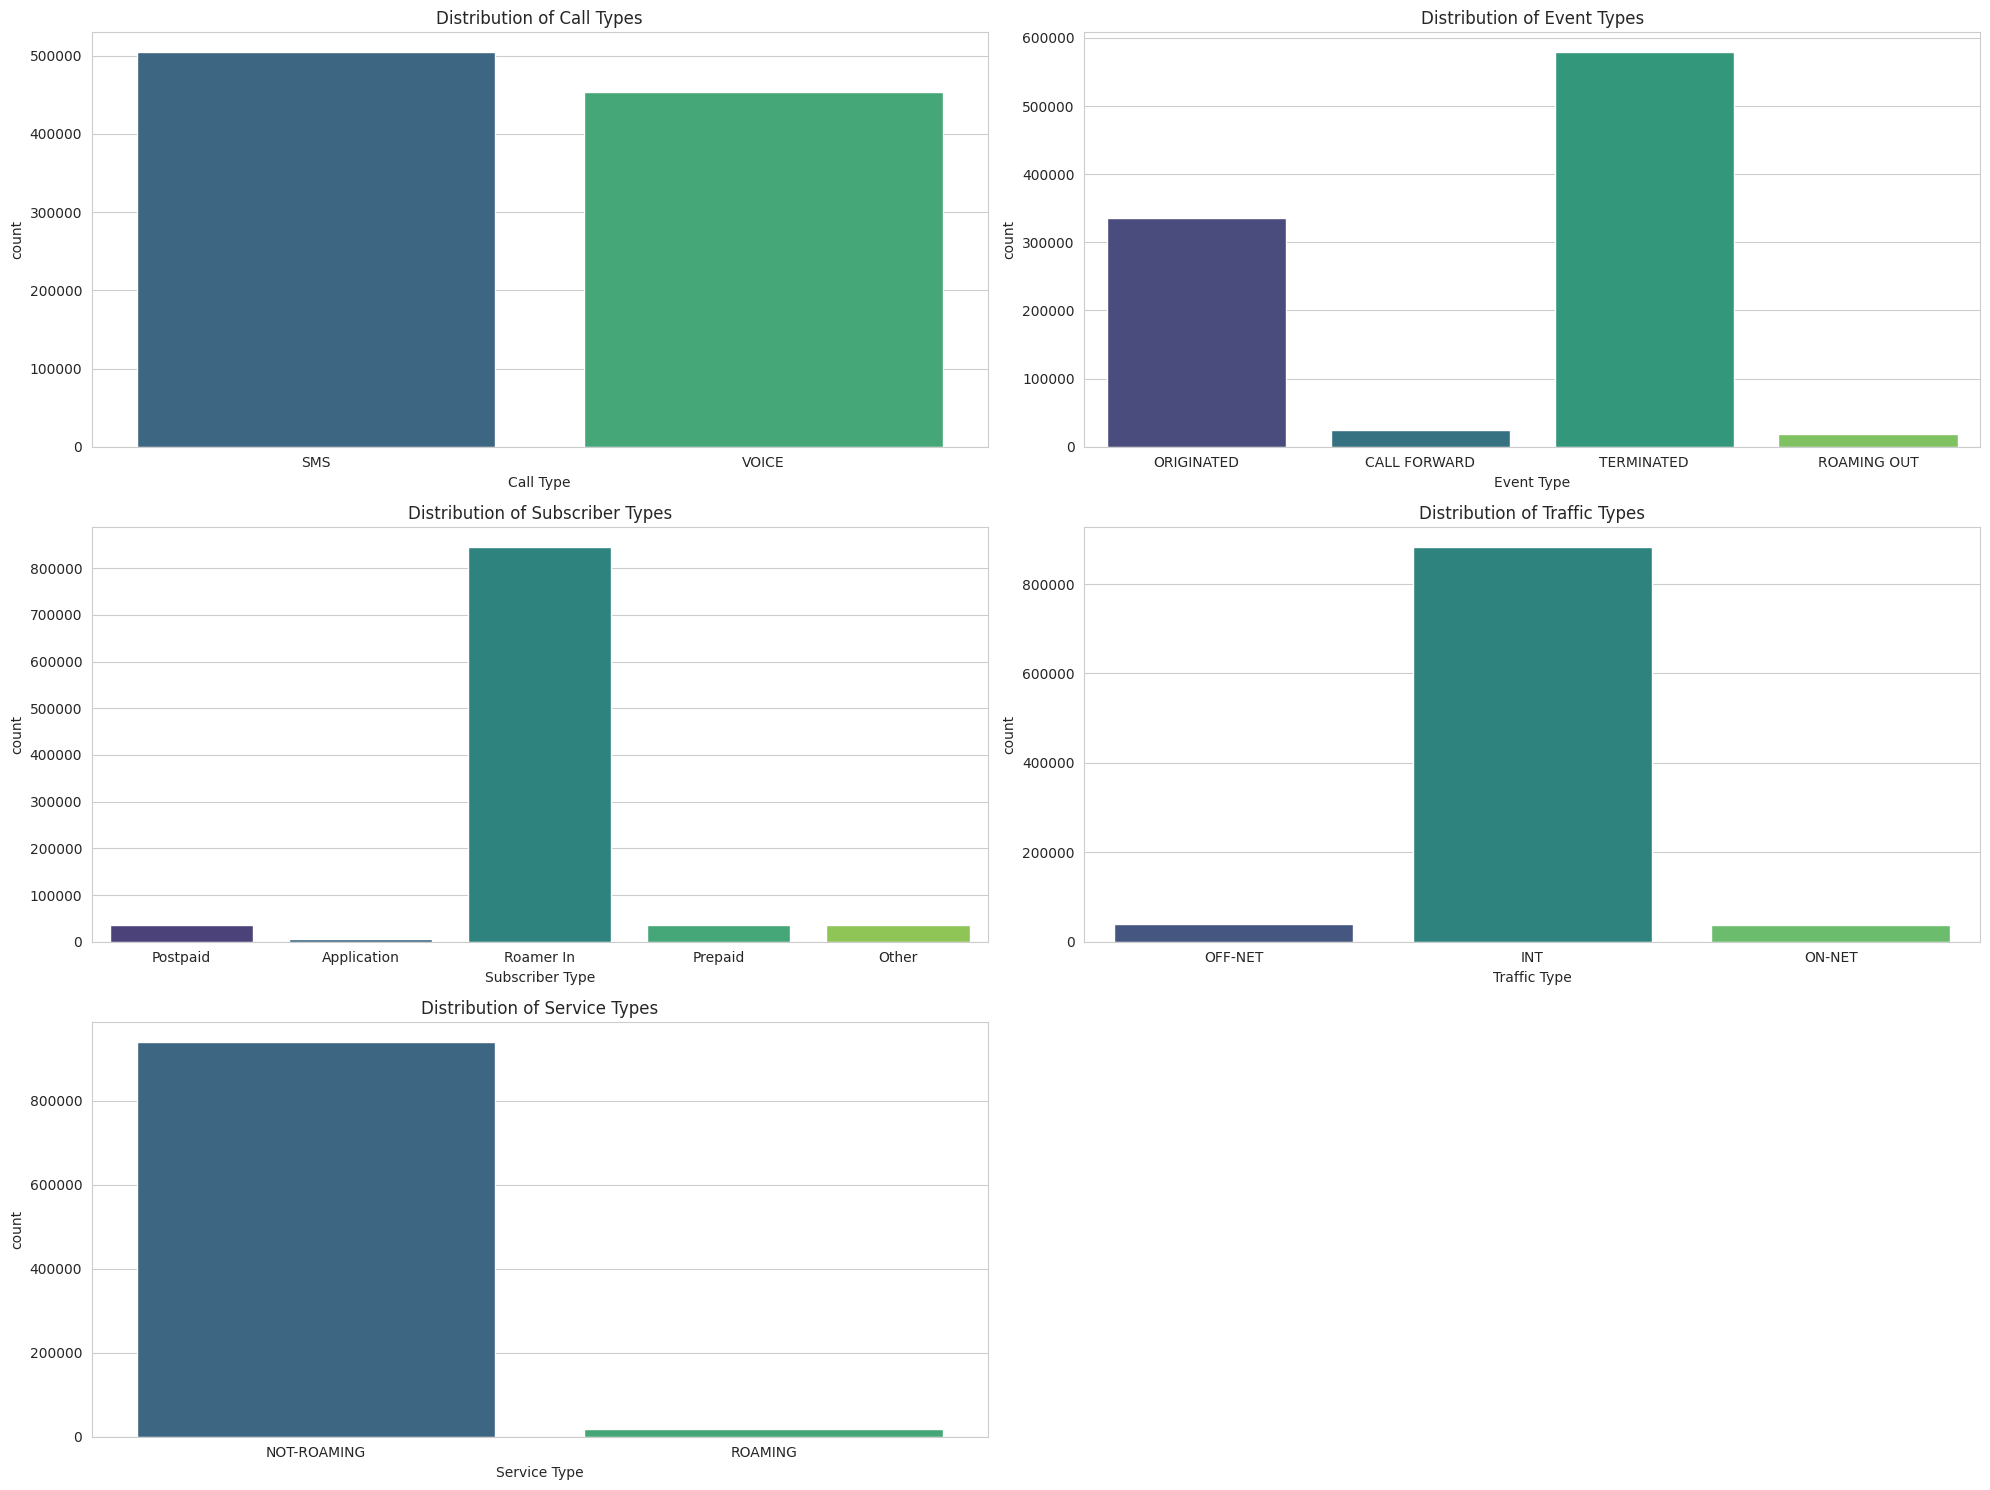

In [9]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure to hold the subplots
plt.figure(figsize=(20, 15))

# Distribution of Call Types
plt.subplot(3, 2, 1)
sns.countplot(x='Call Type', data=df, palette='viridis')
plt.title('Distribution of Call Types')

# Distribution of Event Types
plt.subplot(3, 2, 2)
sns.countplot(x='Event Type', data=df, palette='viridis')
plt.title('Distribution of Event Types')

# Distribution of Subscriber Types
plt.subplot(3, 2, 3)
sns.countplot(x='Subscriber Type', data=df, palette='viridis')
plt.title('Distribution of Subscriber Types')

# Distribution of Traffic Types
plt.subplot(3, 2, 4)
sns.countplot(x='Traffic Type', data=df, palette='viridis')
plt.title('Distribution of Traffic Types')

# Distribution of Service Types
plt.subplot(3, 2, 5)
sns.countplot(x='Service Type', data=df, palette='viridis')
plt.title('Distribution of Service Types')

# Adjust layout to make room for the titles and prevent overlap
plt.tight_layout()
plt.savefig('Distribuition.png')  # Replace with your path and desired file name

# If you're using Jupyter notebooks or IPython, you might also need to close the figure explicitly

plt.show()
plt.close()

In [10]:
from ydata_profiling import ProfileReport

/opt/conda/lib/python3.10/site-packages/numba/core/decorators.py:262: NumbaDeprecationWarning: numba.generated_jit is deprecated. Please see the documentation at: https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-generated-jit for more information and advice on a suitable replacement.
  warnings.warn(msg, NumbaDeprecationWarning)
/opt/conda/lib/python3.10/site-packages/visions/backends/shared/nan_handling.py:51: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def hasna(x: np.ndarray) -> bool:


In [11]:
profile = ProfileReport(df.reset_index(), title='Pandas Profiling Report', explorative=True)

# Save the report to an HTML file
profile.to_file('ydata_profiling_report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]